# Matplotlib Project: Final Expense Analysis

## Step 1: Load the csv file into a dataframe

In [92]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

csv_path = (
    Path.cwd()
    / "data"
    / "final_expense_analysis.csv"
)

df = pd.read_csv(csv_path)
df["date"] = pd.to_datetime(df["date"])

df.head()

,date,category,amount,spending_level,category_average,difference_from_category_average
0,2026-01-02,Food,250,Medium,260.0,-10.0
1,2026-01-03,Transport,120,Low,135.0,-15.0
2,2026-01-03,Food,300,Medium,260.0,40.0
3,2026-01-05,Shopping,800,High,700.0,100.0
4,2026-01-06,Bills,1000,High,950.0,50.0


## Step 2: Inspect the dataset
**Cell 1 — Check the structure**

In [93]:
print(f"Dataframe Shape: {df.shape}\n")
df.info()

Dataframe Shape: (12, 6)

<class 'pandas.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype         
---  ------                            --------------  -----         
 0   date                              12 non-null     datetime64[us]
 1   category                          12 non-null     str           
 2   amount                            12 non-null     int64         
 3   spending_level                    12 non-null     str           
 4   category_average                  12 non-null     float64       
 5   difference_from_category_average  12 non-null     float64       
dtypes: datetime64[us](1), float64(2), int64(1), str(2)
memory usage: 708.0 bytes


**Cell 2 — Check the statistics**

In [94]:
df.describe()

,date,amount,category_average,difference_from_category_average
count,12,12.000000,12.000000,12.000000
mean,2026-01-09 08:00:00,443.333333,443.333333,0.000000
min,2026-01-02 00:00:00,120.000000,135.000000,-100.000000
25%,2026-01-04 12:00:00,210.000000,260.000000,-42.500000
50%,2026-01-09 00:00:00,325.000000,260.000000,-5.000000
75%,2026-01-13 12:00:00,650.000000,700.000000,42.500000
max,2026-01-18 00:00:00,1000.000000,950.000000,100.000000
std,NaN,308.466392,302.025987,62.704212


**Cell 3 — Check categories and missing values**

In [95]:
df["category"].value_counts()

category
Food             5
Transport        2
Shopping         2
Bills            2
Entertainment    1
Name: count, dtype: int64

In [96]:
df.isnull().sum()

date                                0
category                            0
amount                              0
spending_level                      0
category_average                    0
difference_from_category_average    0
dtype: int64

## Step 3: Check the columns

In [97]:
df.columns

Index(['date', 'category', 'amount', 'spending_level', 'category_average',
       'difference_from_category_average'],
      dtype='str')

We already know the dataset includes date, category, amount, spending_level, category_average, and difference_from_category_average.

Our first visualization will be a category-wise expense chart. Before we create it, we'll decide whether the chart should show the total spending per category or the average transaction amount per category. For this project, I recommend starting with total spending per category, because it answers the practical question: Which categories account for the most expenses?

## Step 4: Plotting

### Visualization 1: Category-wise Total Expenses.
**Step 1: Calculate total expenses by category**

In [98]:
category_totals = df.groupby("category")["amount"].sum().sort_values(ascending=False)

category_totals

category
Bills            1900
Shopping         1400
Food             1300
Entertainment     450
Transport         270
Name: amount, dtype: int64

**Step 2: Create the bar chart**
Now it's your turn to plot category_totals using Matplotlib.

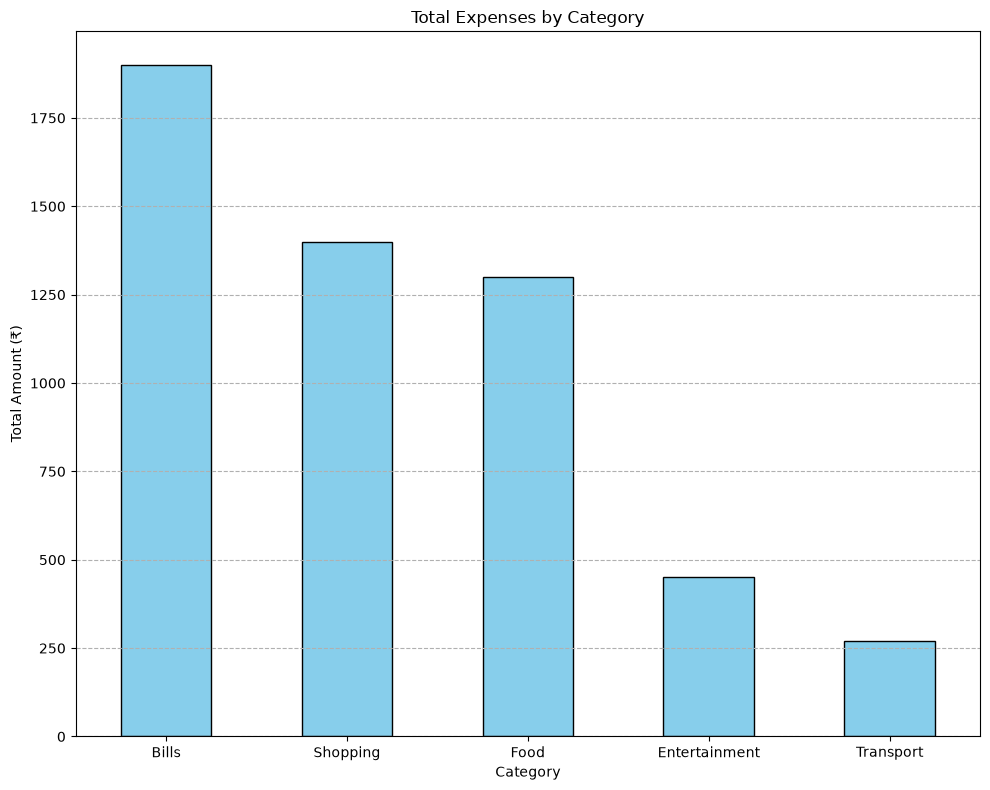

In [99]:
plt.figure(figsize=(10, 8))

category_totals.plot(
    kind="bar",
    color="skyblue",
    edgecolor="black",
)

plt.title("Total Expenses by Category")
plt.xlabel("Category")
plt.ylabel("Total Amount (₹)")
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=1)

plt.tight_layout()

plt.show()

### Visualization 2: Daily Expense Trend
Next, we'll visualize how your expenses change over time.

**Step 1: calculate the total amount spent on each date and store it in daily_expenses.**

In [100]:
daily_expenses = df.groupby("date")["amount"].sum()

daily_expenses

date
2026-01-02     250
2026-01-03     420
2026-01-05     800
2026-01-06    1000
2026-01-08     180
2026-01-10     150
2026-01-12     350
2026-01-13     450
2026-01-15     600
2026-01-17     900
2026-01-18     220
Name: amount, dtype: int64

**Stap 2: Now create a line plot using daily_expenses.**

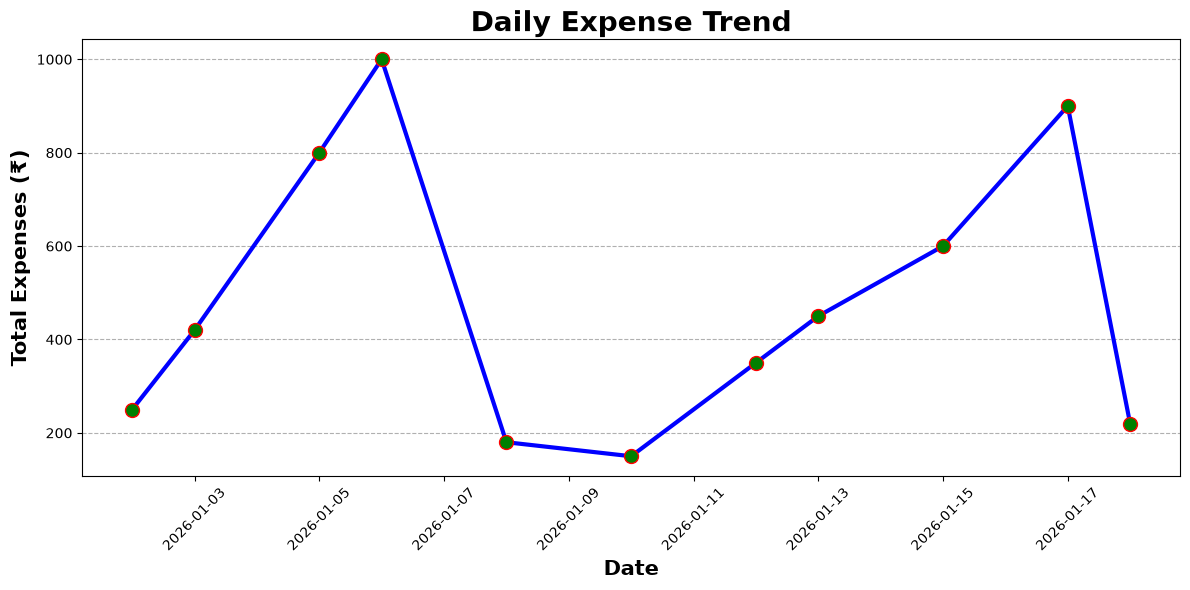

In [101]:
plt.figure(figsize=(12, 6))

plt.plot(
    daily_expenses.index,
    daily_expenses.values,
    color="blue",
    linestyle="-",
    lw=3,
    marker="o",
    markerfacecolor="green",
    markeredgecolor="red",
    markersize=10
)

plt.title("Daily Expense Trend", fontsize=20, fontweight="bold")
plt.xlabel("Date", fontsize=15, fontweight="bold")
plt.ylabel("Total Expenses (₹)", fontsize=15, fontweight="bold")
plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=1)

plt.tight_layout()

plt.show()

### Visualization 3: Expense Amount Distribution
Next, we'll use a histogram to understand how frequently different expense amounts occur.

For example, are most transactions small, medium-sized, or large?
First, let's understand the data we'll plot.

**Your task is to create a histogram using df["amount"].**

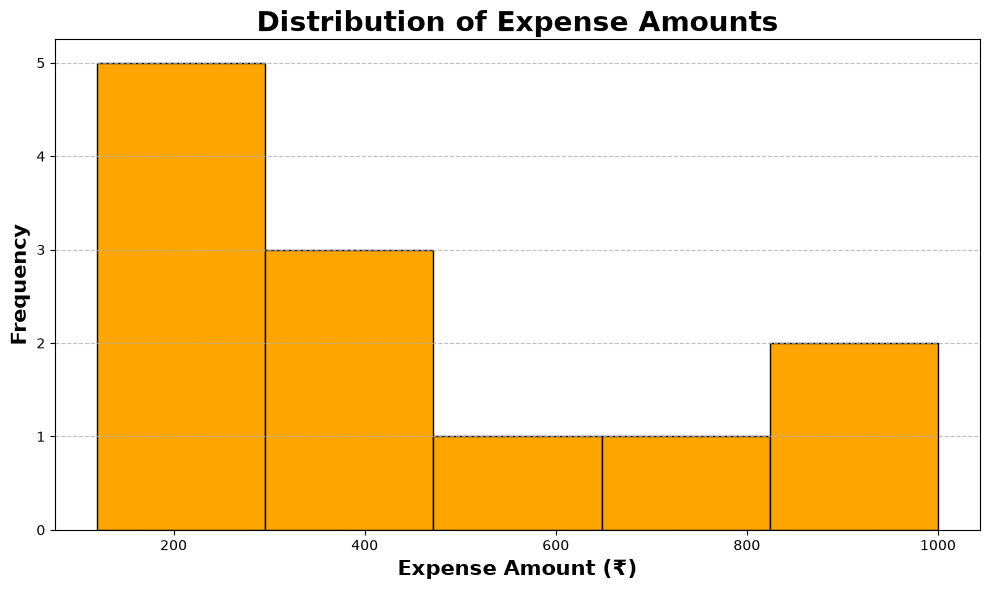

In [102]:
plt.figure(figsize=(10, 6))

plt.hist(
    df["amount"],
    bins=5,
    color="orange",
    edgecolor="black"
)

plt.title("Distribution of Expense Amounts", fontsize=20, fontweight="bold")
plt.xlabel("Expense Amount (₹)", fontsize=15, fontweight="bold")
plt.ylabel("Frequency", fontsize=15, fontweight="bold")
plt.grid(axis="y", linestyle="--", alpha=0.8)

plt.tight_layout()

plt.show()

### Visualization 4: Actual Expenses vs. Category Average
Now let's use the additional columns in your CSV. This visualization will help you compare each transaction's amount with its category's average expense.

Your dataset contains:
- amount — the actual transaction amount.
- category_average — the average expense for that transaction's category.

**Your task: create a scatter plot:**

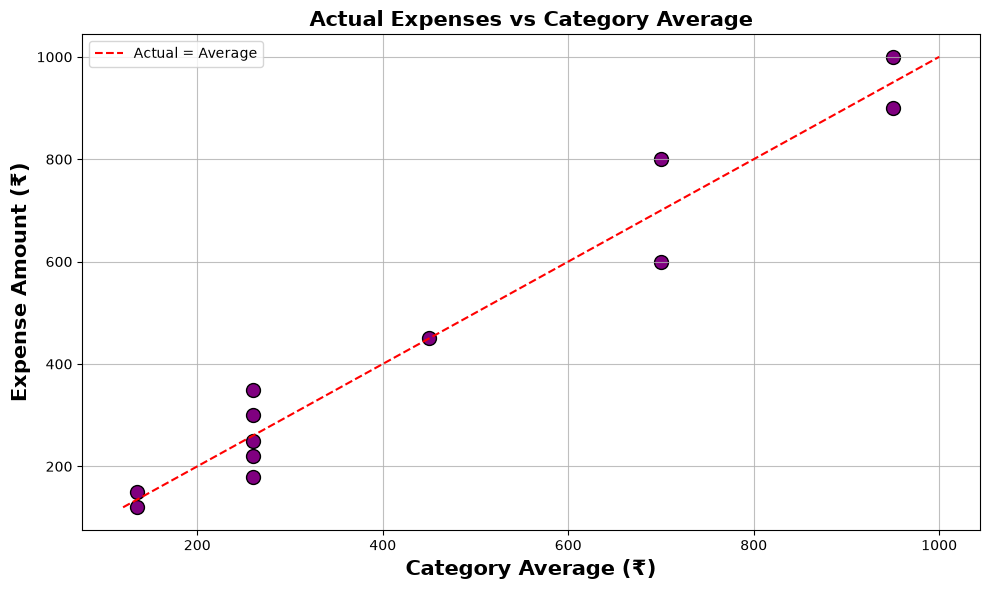

In [103]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df["category_average"],
    df["amount"],
    color="purple",
    edgecolor="black",
    s=100
)

plt.title("Actual Expenses vs Category Average", fontsize=15, fontweight="bold")
plt.xlabel("Category Average (₹)", fontsize=15, fontweight="bold")
plt.ylabel("Expense Amount (₹)", fontsize=15, fontweight="bold")
plt.grid(axis="both", linestyle="-", alpha=0.8)

limits = [
    min(df["category_average"].min(), df["amount"].min()),
    max(df["category_average"].max(), df["amount"].max())
]

plt.plot(
    limits,
    limits,
    color="red",
    linestyle="--",
    label="Actual = Average"
)
plt.legend()

plt.tight_layout()

plt.show()

The red line represents the point where the actual expense equals the category average.
- Above the line: actual expense is greater than the category average.
- Below the line: actual expense is less than the category average.
- On the line: actual expense equals the category average.

### Visualization 5: Spending-level analysis
Let's use the spending_level column for this chart. This chart will show how many transactions are classified as Low, Medium, or High.

In [104]:
df["spending_level"].value_counts()

spending_level
Medium    5
High      4
Low       3
Name: count, dtype: int64

A bar chart is a good choice because it makes comparing the number of transactions in each category easy.

**Your task is to create a bar chart using the output of value_counts().**

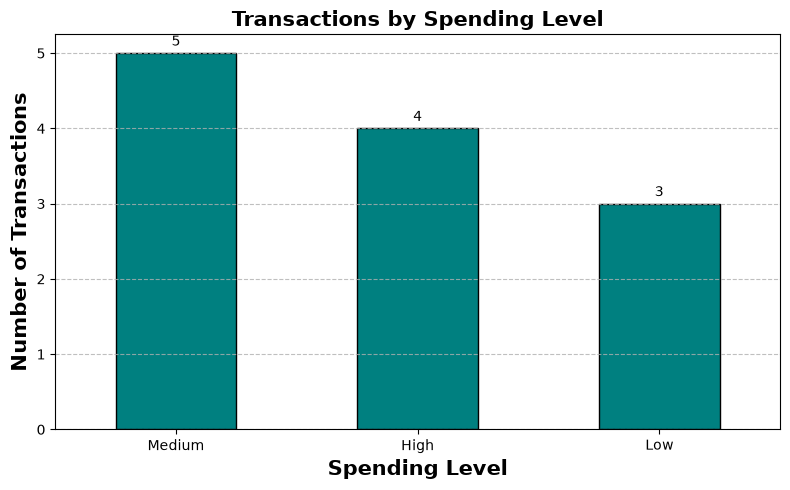

In [105]:
spending_counts = df["spending_level"].value_counts()

fig, ax = plt.subplots(figsize=(8, 5))

spending_counts.plot(
    kind="bar",
    color="teal",
    edgecolor="black",
    ax=ax
)

ax.set_title("Transactions by Spending Level", fontsize=15, fontweight="bold")
ax.set_xlabel("Spending Level", fontsize=15, fontweight="bold")
ax.set_ylabel("Number of Transactions", fontsize=15, fontweight="bold")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", linestyle="--", alpha=0.8)

ax.bar_label(ax.containers[0], padding=3)

plt.tight_layout()
plt.show()

### Visualization 6: Pie chart (Donut chart)
The pie chart will show the category with it's total expense beatifully.

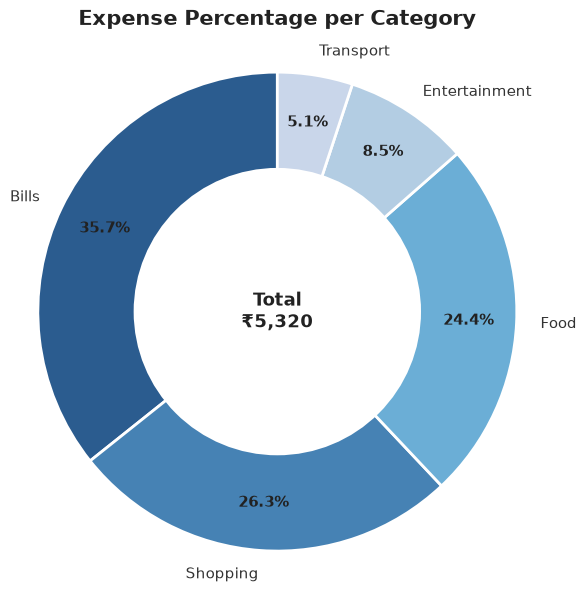

In [106]:
plt.figure(figsize=(6, 6))

categories = category_totals.index
category_expense = category_totals.values

color = ['#2b5c8f', '#4682b4', '#6baed6', '#b3cde3', '#c9d6ea'][:len(categories)]

wedges, texts, autotexts = plt.pie(
    category_totals,
    labels=categories,
    autopct="%1.1f%%",
    startangle=90,
    colors=color,
    pctdistance=0.80,
    wedgeprops={'linewidth': 2, 'edgecolor': 'white'},
    textprops={'fontsize': 11, 'color': '#333333'}
)

for autotext in autotexts:
    autotext.set_color('#222222')
    autotext.set_weight('bold')

centre_circle = plt.Circle((0, 0), 0.60, fc='white')
plt.gca().add_artist(centre_circle)

total_expenses = category_totals.sum()

plt.text(
    0, 0,
    f"Total\n₹{total_expenses:,.0f}",
    ha="center",
    va="center",
    fontsize=13,
    fontweight="bold",
    color="#222222"
)

plt.title("Expense Percentage per Category", fontsize=15, pad=20, weight="bold", color="#222222")
plt.axis("equal")

plt.tight_layout()

plt.show()

**Important Notice:** This Pie chart is advanced and it is often use by companies, So before running it try to understand it.

# Step 5: Create a dashboard

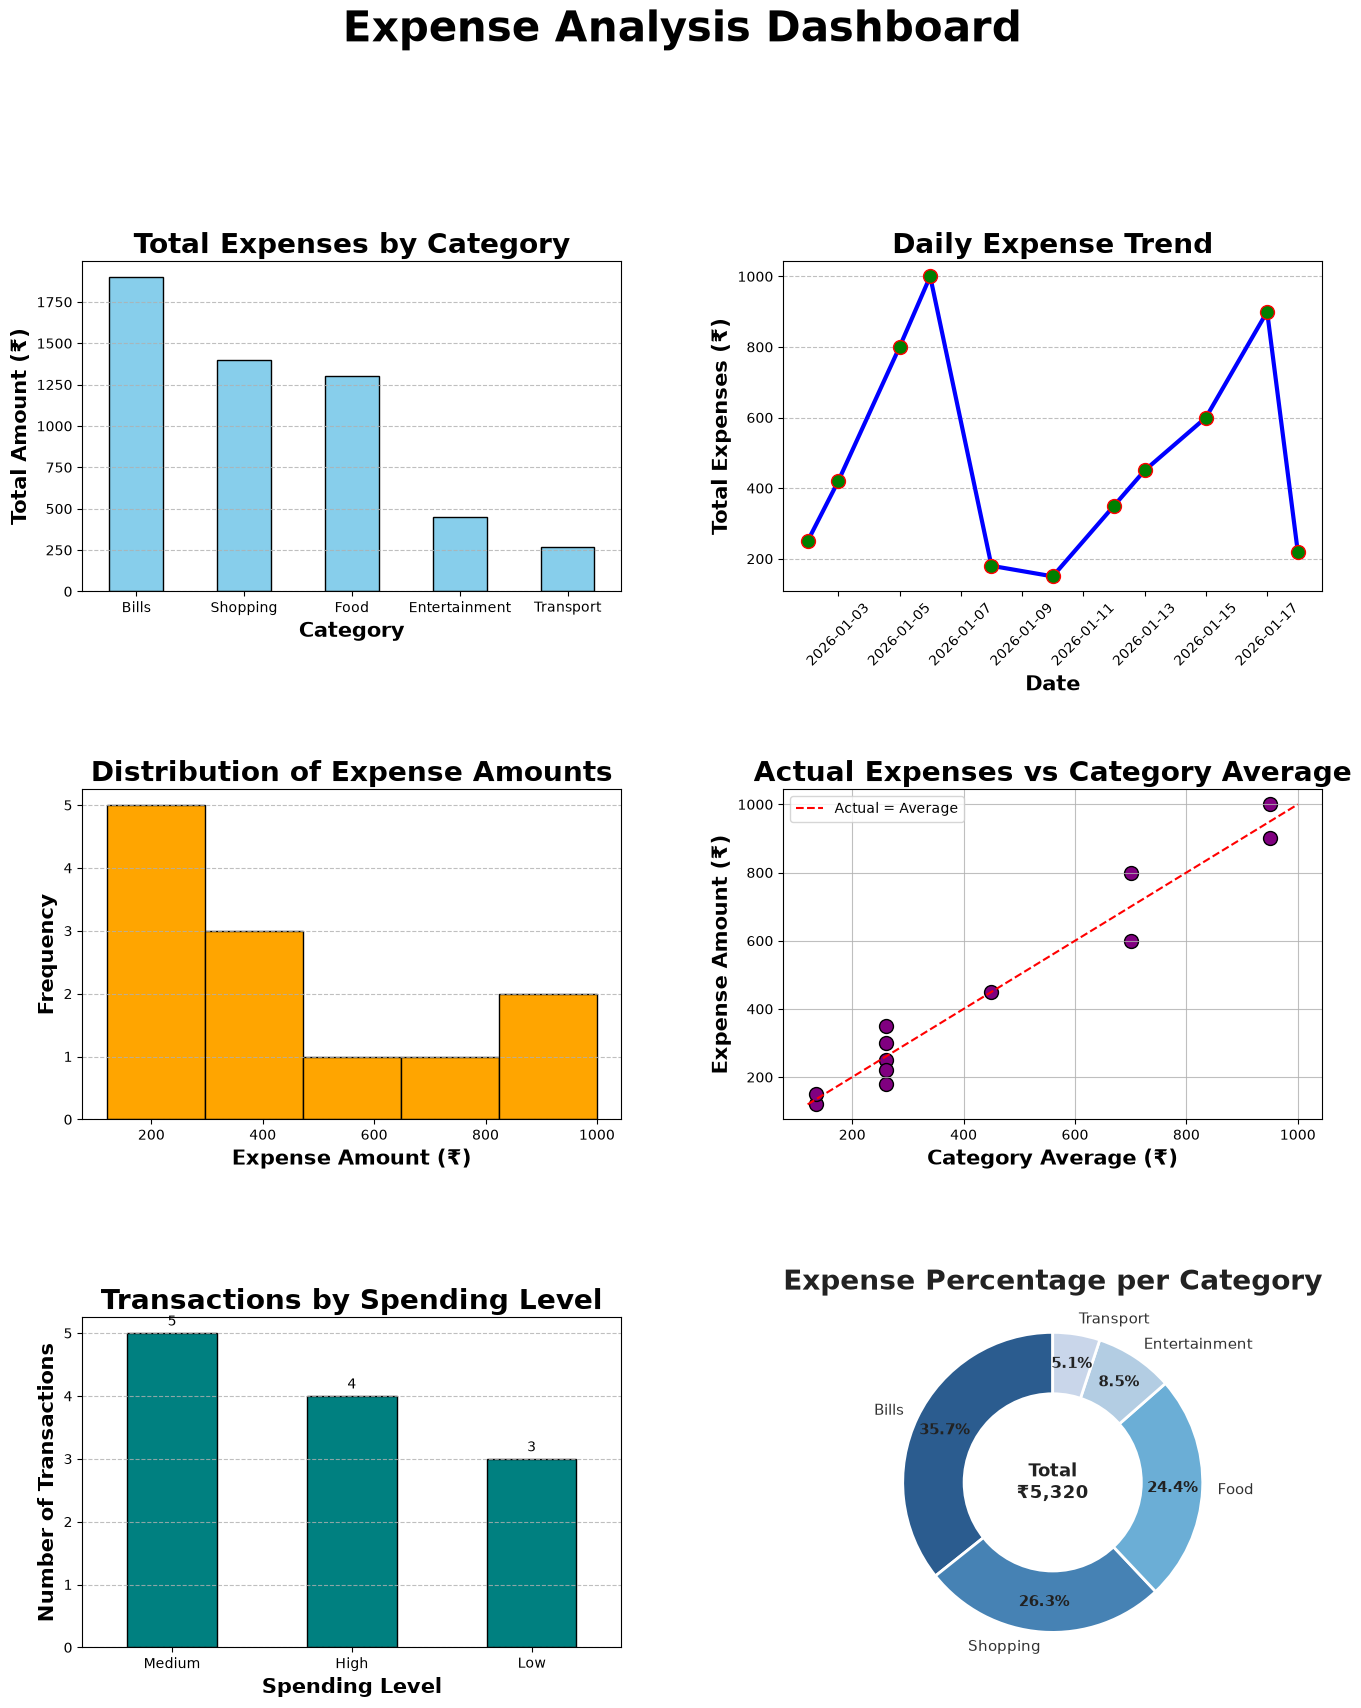

In [156]:
fig, ax = plt.subplots(3, 2, figsize=(16, 18))

fig.suptitle(
    "Expense Analysis Dashboard",
    fontsize=30,
    fontweight="bold",
    y=1.02
)

# Category-wise total expenses
category_totals.plot(
    kind="bar",
    color="skyblue",
    edgecolor="black",
    ax=ax[0, 0]
)

ax[0, 0].set_title("Total Expenses by Category", fontsize=20, fontweight="bold")
ax[0, 0].set_xlabel("Category", fontsize=15, fontweight="bold")
ax[0, 0].set_ylabel("Total Amount (₹)", fontsize=15, fontweight="bold")
ax[0, 0].tick_params(axis="x", rotation=0)
ax[0, 0].grid(axis="y", linestyle="--", alpha=0.8)

# Daily expense trend
ax[0, 1].plot(
    daily_expenses.index,
    daily_expenses.values,
    color="blue",
    linestyle="-",
    lw=3,
    marker="o",
    markerfacecolor="green",
    markeredgecolor="red",
    markersize=10
)

ax[0, 1].set_title("Daily Expense Trend", fontsize=20, fontweight="bold")
ax[0, 1].set_xlabel("Date", fontsize=15, fontweight="bold")
ax[0, 1].set_ylabel("Total Expenses (₹)", fontsize=15, fontweight="bold")
ax[0, 1].tick_params(axis="x", rotation=45)
ax[0, 1].grid(axis="y", linestyle="--", alpha=0.8)

# Expense Amount Distribution
ax[1, 0].hist(
    df["amount"],
    bins=5,
    color="orange",
    edgecolor="black"
)

ax[1, 0].set_title("Distribution of Expense Amounts", fontsize=20, fontweight="bold")
ax[1, 0].set_xlabel("Expense Amount (₹)", fontsize=15, fontweight="bold")
ax[1, 0].set_ylabel("Frequency", fontsize=15, fontweight="bold")
ax[1, 0].grid(axis="y", linestyle="--", alpha=0.8)

# Actual Expenses vs. Category Average
ax[1, 1].scatter(
    df["category_average"],
    df["amount"],
    color="purple",
    edgecolor="black",
    s=100
)

ax[1, 1].set_title("Actual Expenses vs Category Average", fontsize=20, fontweight="bold")
ax[1, 1].set_xlabel("Category Average (₹)", fontsize=15, fontweight="bold")
ax[1, 1].set_ylabel("Expense Amount (₹)", fontsize=15, fontweight="bold")
ax[1, 1].grid(axis="both", linestyle="-", alpha=0.8)

limits = [
    min(df["category_average"].min(), df["amount"].min()),
    max(df["category_average"].max(), df["amount"].max())
]

ax[1, 1].plot(
    limits,
    limits,
    color="red",
    linestyle="--",
    label="Actual = Average"
)

ax[1, 1].legend()

# Spending-level analysis
spending_counts.plot(
    kind="bar",
    color="teal",
    edgecolor="black",
    ax=ax[2, 0]
)

ax[2, 0].set_title("Transactions by Spending Level", fontsize=20, fontweight="bold")
ax[2, 0].set_xlabel("Spending Level", fontsize=15, fontweight="bold")
ax[2, 0].set_ylabel("Number of Transactions", fontsize=15, fontweight="bold")
ax[2, 0].tick_params(axis="x", rotation=0)
ax[2, 0].grid(axis="y", linestyle="--", alpha=0.8)

ax[2, 0].bar_label(ax[2, 0].containers[0], padding=3)

# Pie chart (Donut chart)
category_totals = df.groupby("category")["amount"].sum().sort_values(ascending=False)

categories = category_totals.index
category_expense = category_totals.values

color = ['#2b5c8f', '#4682b4', '#6baed6', '#b3cde3', '#c9d6ea'][:len(categories)]

wedges, texts, autotexts = ax[2, 1].pie(
    category_totals,
    labels=categories,
    autopct="%1.1f%%",
    startangle=90,
    colors=color,
    pctdistance=0.80,
    wedgeprops={'linewidth': 2, 'edgecolor': 'white'},
    textprops={'fontsize': 11, 'color': '#333333'}
)

for autotext in autotexts:
    autotext.set_color('#222222')
    autotext.set_weight('bold')

centre_circle = plt.Circle((0, 0), 0.60, fc='white')
ax[2, 1].add_artist(centre_circle)

total_expenses = category_totals.sum()

ax[2, 1].text(
    0, 0,
    f"Total\n₹{total_expenses:,.0f}",
    ha="center",
    va="center",
    fontsize=13,
    fontweight="bold",
    color="#222222"
)

ax[2, 1].set_title("Expense Percentage per Category", fontsize=20, pad=20, weight="bold", color="#222222")
ax[2, 1].axis("equal")

plt.subplots_adjust(
    hspace=0.6,  # Vertical spacing between rows
    wspace=0.3   # Horizontal spacing between columns
)

plt.show()